Break dates: ['2021-12-13', '2021-12-20', '2022-01-04', '2022-01-19']
Break indices: [12, 19, 34, 49]
Segment bounds: [(0, 12), (12, 19), (19, 34), (34, 49), (49, 63)]
Policy date: 2022-01-19 index: 49


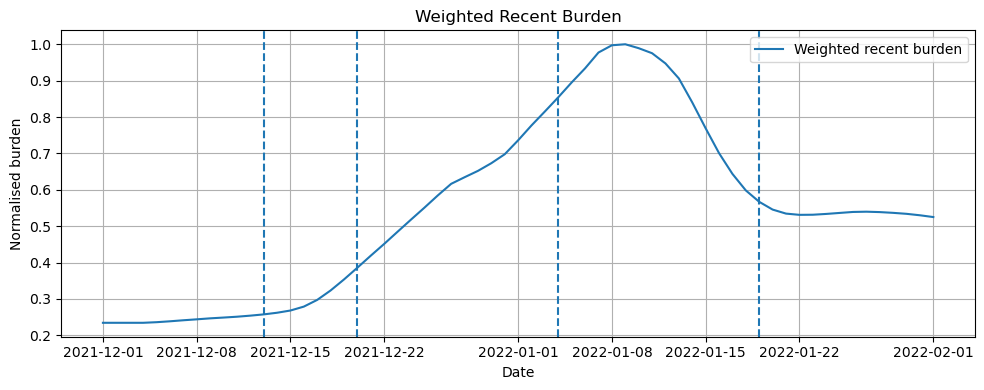


Factual fitting finished
Success: True
Message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
rho: 1.134726363828469
I0: 197113.5714386302
gamma: 0.14285714285714285
MSE: 82937305.31597331
RMSE: 9106.99211133804
log_MSE: 0.005338989750996497

Estimated factual segment parameters:
Segment 1: beta0 = 0.285150, k = 0.614733, h = 0.000001
Segment 2: beta0 = 0.381349, k = 0.837063, h = 0.027153
Segment 3: beta0 = 0.309857, k = 0.681424, h = 0.113232
Segment 4: beta0 = 0.175558, k = 1.643626, h = 2.500334
Segment 5: beta0 = 0.228922, k = 1.028882, h = 0.326271

Counterfactual: keep Segment 4 beta formula after 19 Jan
Factual after 19 Jan: Segment 5 beta formula
Counterfactual after 19 Jan: Segment 4 beta formula

Post-19 Jan fitted cases
Factual cumulative fitted cases: 1237464.0176651492
Counterfactual cumulative fitted cases: 1197773.4598107869
Difference factual - counterfactual: 39690.5578543623
Percentage reduction under counterfactual: 3.2074110671315164 %

Post-19 Jan incidence
Fac

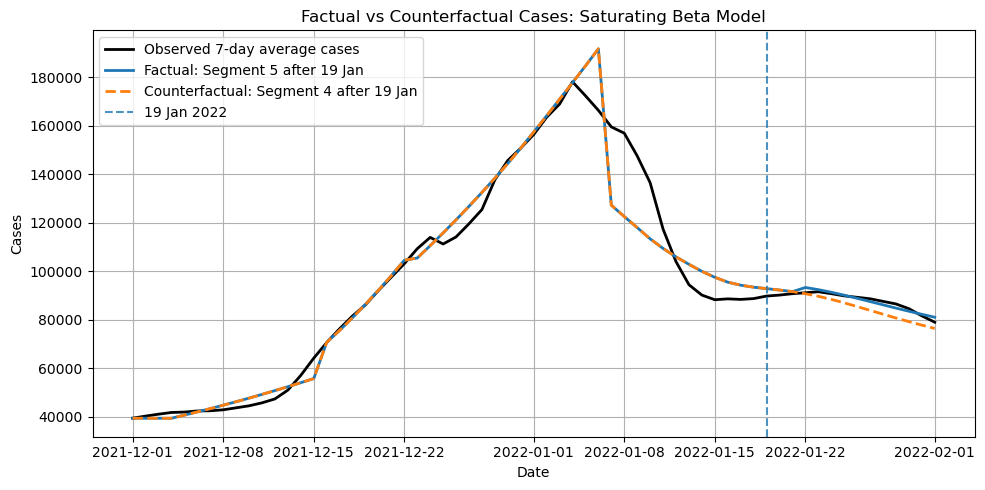

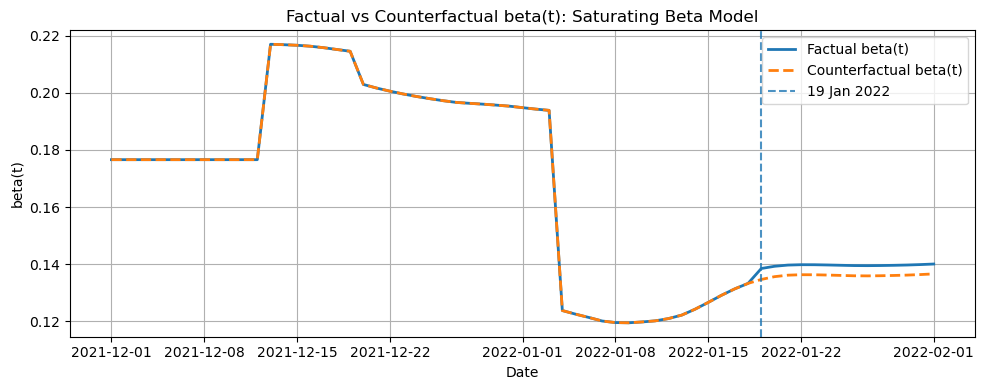

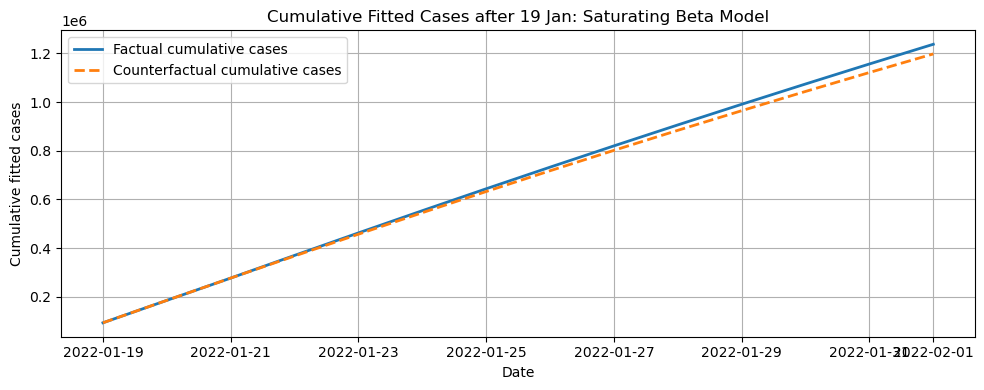


Saved:
../results/sat_counterfactual_segment4_cases.png
../results/sat_counterfactual_segment4_beta.png
../results/sat_counterfactual_segment4_cumulative.png
../results/sat_counterfactual_segment4_summary.csv
../results/sat_counterfactual_segment4_paths.csv

Interpretation helper:
The counterfactual path has fewer fitted cases after 19 Jan. Under this model, keeping the Segment 4 beta formula would reduce transmission.
This is a model-based counterfactual comparison. It changes the post-19 Jan beta formula, but it does not identify a pure causal policy effect.


In [1]:
# =========================================================
# Saturating beta fitting + counterfactual using Segment 4 beta formula
#
# Factual model:
#   beta_j(t) = beta0_j / (1 + k_j * B(t) / (h_j + B(t)))
#
# Counterfactual model:
#   Before 19 Jan, same as factual model.
#   After 19 Jan, keep using Segment 4 beta formula:
#       beta_cf(t) = beta0_4 / (1 + k_4 * B(t) / (h_4 + B(t)))
#
# No new beta0 is introduced for the counterfactual period.
# =========================================================

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

os.makedirs("../results", exist_ok=True)

# =========================================================
# BLOCK 1: data + weighted recent burden
# =========================================================

df = pd.read_csv("../data/uk_final.csv")
df["date"] = pd.to_datetime(df["date"])

df_fit = df[(df["date"] >= "2021-12-01") & (df["date"] <= "2022-02-01")].copy()
df_fit = df_fit.reset_index(drop=True)

dates = df_fit["date"].reset_index(drop=True)
obs_cases = df_fit["cases_7d"].values.astype(float)
T = len(obs_cases)

tau = 3
gamma = 1 / 7
N = 67_000_000

break_dates = ["2021-12-13", "2021-12-20", "2022-01-04", "2022-01-19"]
break_indices = [int(np.where(dates == pd.Timestamp(d))[0][0]) for d in break_dates]

policy_date = pd.Timestamp("2022-01-19")
policy_idx = int(np.where(dates == policy_date)[0][0])


def get_segment_bounds(T, break_indices):
    bounds = [0] + break_indices + [T]
    return [(bounds[i], bounds[i + 1]) for i in range(len(bounds) - 1)]


segment_bounds = get_segment_bounds(T, break_indices)
n_seg = len(segment_bounds)

print("Break dates:", break_dates)
print("Break indices:", break_indices)
print("Segment bounds:", segment_bounds)
print("Policy date:", policy_date.strftime("%Y-%m-%d"), "index:", policy_idx)


def apply_delay(x, tau):
    y = np.empty_like(x)
    if tau <= 0:
        return x.copy()
    y[:tau] = x[0]
    y[tau:] = x[:-tau]
    return y


obs_delayed = apply_delay(obs_cases, tau)

# =========================================================
# Weighted recent burden
# =========================================================

L = 7
lam = 0.75

weights = np.array([lam ** ell for ell in range(L)], dtype=float)
weights = weights / weights.sum()

burden = np.zeros(T)

for t in range(T):
    vals = []
    wts = []

    for ell in range(L):
        idx = t - ell
        if idx >= 0:
            vals.append(obs_delayed[idx])
            wts.append(weights[ell])

    vals = np.array(vals, dtype=float)
    wts = np.array(wts, dtype=float)
    wts = wts / wts.sum()

    burden[t] = np.sum(wts * vals)

# normalize burden to [0, 1]
burden = burden / np.max(burden)

plt.figure(figsize=(10, 4))
plt.plot(dates, burden, label="Weighted recent burden")
for d in break_dates:
    plt.axvline(pd.Timestamp(d), linestyle="--")
plt.legend()
plt.title("Weighted Recent Burden")
plt.xlabel("Date")
plt.ylabel("Normalised burden")
plt.grid()
plt.tight_layout()
plt.show()

# =========================================================
# BLOCK 2: saturating beta model
# =========================================================


def get_segment_index(t, segment_bounds):
    for j, (a, b) in enumerate(segment_bounds):
        if a <= t < b:
            return j
    return len(segment_bounds) - 1


# Saturating beta formula:
# beta_j(t) = beta0_j / (1 + k_j * B(t) / (h_j + B(t)))

def beta_formula(B, p):
    beta0 = p["beta0"]
    k = p["k"]
    h = p["h"]

    beta = beta0 / (1.0 + (k * B) / (h + B))
    return max(1e-8, beta)


# factual beta function:
# each segment uses its own beta0_j, k_j, h_j

def beta_t_factual(t, params):
    j = get_segment_index(t, segment_bounds)
    p = params[j]
    B = burden[t]
    return beta_formula(B, p)


# counterfactual beta function:
# before 19 Jan, same as factual;
# after 19 Jan, keep using Segment 4 formula.
# Python indexing starts from 0, so params[3] is Segment 4.

def beta_t_keep_segment4(t, params):
    if t >= policy_idx:
        p = params[3]
    else:
        j = get_segment_index(t, segment_bounds)
        p = params[j]

    B = burden[t]
    return beta_formula(B, p)


# unpack parameters
# theta = [
#   beta0_1, k_1, h_1,
#   beta0_2, k_2, h_2,
#   ...
#   beta0_5, k_5, h_5,
#   rho, I0
# ]

def unpack(theta):
    params = []
    pos = 0

    for _ in range(n_seg):
        params.append({
            "beta0": theta[pos],
            "k": theta[pos + 1],
            "h": theta[pos + 2],
        })
        pos += 3

    rho = theta[pos]
    I0 = theta[pos + 1]

    return params, rho, I0


# =========================================================
# BLOCK 3: discrete-time SIR simulation
# =========================================================


def simulate(theta, beta_function):
    params, rho, I0 = unpack(theta)

    S = np.zeros(T)
    I = np.zeros(T)
    R = np.zeros(T)
    beta_path = np.zeros(T)
    incidence = np.zeros(T)

    S[0] = N - I0
    I[0] = I0
    R[0] = 0.0

    for t in range(T):
        b = beta_function(t, params)
        beta_path[t] = b

        incidence[t] = b * S[t] * I[t] / N

        if t < T - 1:
            new_inf = incidence[t]
            new_rec = gamma * I[t]

            S[t + 1] = max(0.0, S[t] - new_inf)
            I[t + 1] = max(0.0, I[t] + new_inf - new_rec)
            R[t + 1] = max(0.0, R[t] + new_rec)

    fitted_cases = rho * apply_delay(incidence, tau)

    return {
        "S": S,
        "I": I,
        "R": R,
        "beta_path": beta_path,
        "incidence": incidence,
        "fitted_cases": fitted_cases,
        "params": params,
        "rho": rho,
        "I0": I0,
    }


# =========================================================
# BLOCK 4: factual fitting
# =========================================================


def loss(theta):
    try:
        sim = simulate(theta, beta_t_factual)
        fitted = sim["fitted_cases"]

        if np.any(np.isnan(fitted)) or np.any(np.isinf(fitted)):
            return 1e10
        if np.any(fitted < 0):
            return 1e10

        return np.mean((np.log(fitted + 1) - np.log(obs_cases + 1)) ** 2)

    except Exception:
        return 1e10


# Initial values and bounds
x0 = []
bounds = []

for _ in range(n_seg):
    # beta0_j, k_j, h_j
    x0 += [0.25, 1.0, 0.2]

    # Since B(t) is normalised to [0, 1],
    # h_j is also set to a reasonable positive range.
    bounds += [
        (1e-6, 2.0),      # beta0_j
        (0.0, 50.0),      # k_j
        (1e-6, 5.0),      # h_j
    ]

x0 += [1.0, obs_cases[0] * 5]     # rho, I0
bounds += [
    (1e-6, 10.0),         # rho
    (1.0, 5_000_000.0),   # I0
]

x0 = np.array(x0, dtype=float)

res = minimize(
    loss,
    x0,
    bounds=bounds,
    method="L-BFGS-B",
)

theta_hat = res.x
factual = simulate(theta_hat, beta_t_factual)

mse = np.mean((factual["fitted_cases"] - obs_cases) ** 2)
rmse = np.sqrt(mse)
log_mse = np.mean((np.log(factual["fitted_cases"] + 1) - np.log(obs_cases + 1)) ** 2)

print("\nFactual fitting finished")
print("Success:", res.success)
print("Message:", res.message)
print("rho:", factual["rho"])
print("I0:", factual["I0"])
print("gamma:", gamma)
print("MSE:", mse)
print("RMSE:", rmse)
print("log_MSE:", log_mse)

print("\nEstimated factual segment parameters:")
for j, p in enumerate(factual["params"], start=1):
    print(
        f"Segment {j}: "
        f"beta0 = {p['beta0']:.6f}, "
        f"k = {p['k']:.6f}, "
        f"h = {p['h']:.6f}"
    )


# =========================================================
# BLOCK 5: counterfactual simulation
# =========================================================

counterfactual = simulate(theta_hat, beta_t_keep_segment4)

factual_cases = factual["fitted_cases"]
cf_cases = counterfactual["fitted_cases"]

factual_beta = factual["beta_path"]
cf_beta = counterfactual["beta_path"]

factual_incidence = factual["incidence"]
cf_incidence = counterfactual["incidence"]


# =========================================================
# BLOCK 6: comparison after 19 Jan
# =========================================================

post_mask = np.arange(T) >= policy_idx

cum_factual_cases = np.sum(factual_cases[post_mask])
cum_cf_cases = np.sum(cf_cases[post_mask])
case_diff = cum_factual_cases - cum_cf_cases
case_pct_diff = 100 * case_diff / cum_factual_cases if cum_factual_cases != 0 else np.nan

cum_factual_incidence = np.sum(factual_incidence[post_mask])
cum_cf_incidence = np.sum(cf_incidence[post_mask])
incidence_diff = cum_factual_incidence - cum_cf_incidence
incidence_pct_diff = 100 * incidence_diff / cum_factual_incidence if cum_factual_incidence != 0 else np.nan

mean_factual_beta = np.mean(factual_beta[post_mask])
mean_cf_beta = np.mean(cf_beta[post_mask])
beta_diff = mean_factual_beta - mean_cf_beta
beta_pct_diff = 100 * beta_diff / mean_factual_beta if mean_factual_beta != 0 else np.nan

print("\n=================================================")
print("Counterfactual: keep Segment 4 beta formula after 19 Jan")
print("=================================================")
print("Factual after 19 Jan: Segment 5 beta formula")
print("Counterfactual after 19 Jan: Segment 4 beta formula")

print("\nPost-19 Jan fitted cases")
print("Factual cumulative fitted cases:", cum_factual_cases)
print("Counterfactual cumulative fitted cases:", cum_cf_cases)
print("Difference factual - counterfactual:", case_diff)
print("Percentage reduction under counterfactual:", case_pct_diff, "%")

print("\nPost-19 Jan incidence")
print("Factual cumulative incidence:", cum_factual_incidence)
print("Counterfactual cumulative incidence:", cum_cf_incidence)
print("Difference factual - counterfactual:", incidence_diff)
print("Percentage incidence reduction under counterfactual:", incidence_pct_diff, "%")

print("\nPost-19 Jan beta")
print("Factual mean beta:", mean_factual_beta)
print("Counterfactual mean beta:", mean_cf_beta)
print("Difference factual - counterfactual:", beta_diff)
print("Percentage beta reduction under counterfactual:", beta_pct_diff, "%")


# =========================================================
# BLOCK 7: plots
# =========================================================

plt.figure(figsize=(10, 5))
plt.plot(dates, obs_cases, label="Observed 7-day average cases", linewidth=2, color="black")
plt.plot(dates, factual_cases, label="Factual: Segment 5 after 19 Jan", linewidth=2)
plt.plot(dates, cf_cases, label="Counterfactual: Segment 4 after 19 Jan", linewidth=2, linestyle="--")

plt.axvline(policy_date, linestyle="--", alpha=0.8, label="19 Jan 2022")

plt.title("Factual vs Counterfactual Cases: Saturating Beta Model")
plt.xlabel("Date")
plt.ylabel("Cases")
plt.legend()
plt.grid()
plt.tight_layout()
plt.savefig("../results/sat_counterfactual_segment4_cases.png", dpi=300, bbox_inches="tight")
plt.show()


plt.figure(figsize=(10, 4))
plt.plot(dates, factual_beta, label="Factual beta(t)", linewidth=2)
plt.plot(dates, cf_beta, label="Counterfactual beta(t)", linewidth=2, linestyle="--")

plt.axvline(policy_date, linestyle="--", alpha=0.8, label="19 Jan 2022")

plt.title("Factual vs Counterfactual beta(t): Saturating Beta Model")
plt.xlabel("Date")
plt.ylabel("beta(t)")
plt.legend()
plt.grid()
plt.tight_layout()
plt.savefig("../results/sat_counterfactual_segment4_beta.png", dpi=300, bbox_inches="tight")
plt.show()


post_dates = dates.iloc[policy_idx:].reset_index(drop=True)

plt.figure(figsize=(10, 4))
plt.plot(post_dates, np.cumsum(factual_cases[post_mask]), label="Factual cumulative cases", linewidth=2)
plt.plot(post_dates, np.cumsum(cf_cases[post_mask]), label="Counterfactual cumulative cases", linewidth=2, linestyle="--")

plt.title("Cumulative Fitted Cases after 19 Jan: Saturating Beta Model")
plt.xlabel("Date")
plt.ylabel("Cumulative fitted cases")
plt.legend()
plt.grid()
plt.tight_layout()
plt.savefig("../results/sat_counterfactual_segment4_cumulative.png", dpi=300, bbox_inches="tight")
plt.show()


# =========================================================
# BLOCK 8: save outputs
# =========================================================

summary_df = pd.DataFrame([{
    "counterfactual_assumption": "After 19 Jan, use Segment 4 saturating beta formula instead of Segment 5",
    "factual_cumulative_fitted_cases_post_19jan": cum_factual_cases,
    "counterfactual_cumulative_fitted_cases_post_19jan": cum_cf_cases,
    "case_difference_factual_minus_counterfactual": case_diff,
    "case_pct_reduction_under_counterfactual": case_pct_diff,
    "factual_cumulative_incidence_post_19jan": cum_factual_incidence,
    "counterfactual_cumulative_incidence_post_19jan": cum_cf_incidence,
    "incidence_difference_factual_minus_counterfactual": incidence_diff,
    "incidence_pct_reduction_under_counterfactual": incidence_pct_diff,
    "factual_mean_beta_post_19jan": mean_factual_beta,
    "counterfactual_mean_beta_post_19jan": mean_cf_beta,
    "mean_beta_difference_factual_minus_counterfactual": beta_diff,
    "mean_beta_pct_reduction_under_counterfactual": beta_pct_diff,
}])

summary_df.to_csv("../results/sat_counterfactual_segment4_summary.csv", index=False)

paths_df = pd.DataFrame({
    "date": dates,
    "observed_cases": obs_cases,
    "burden": burden,
    "factual_fitted_cases": factual_cases,
    "counterfactual_fitted_cases": cf_cases,
    "factual_beta": factual_beta,
    "counterfactual_beta": cf_beta,
    "factual_incidence": factual_incidence,
    "counterfactual_incidence": cf_incidence,
})

paths_df.to_csv("../results/sat_counterfactual_segment4_paths.csv", index=False)

print("\nSaved:")
print("../results/sat_counterfactual_segment4_cases.png")
print("../results/sat_counterfactual_segment4_beta.png")
print("../results/sat_counterfactual_segment4_cumulative.png")
print("../results/sat_counterfactual_segment4_summary.csv")
print("../results/sat_counterfactual_segment4_paths.csv")


# =========================================================
# BLOCK 9: interpretation helper
# =========================================================

print("\nInterpretation helper:")
if case_diff > 0:
    print(
        "The counterfactual path has fewer fitted cases after 19 Jan. "
        "Under this model, keeping the Segment 4 beta formula would reduce transmission."
    )
elif case_diff < 0:
    print(
        "The counterfactual path has more fitted cases after 19 Jan. "
        "Under this model, keeping the Segment 4 beta formula does not reduce transmission."
    )
else:
    print(
        "The factual and counterfactual paths are almost identical after 19 Jan."
    )

print(
    "This is a model-based counterfactual comparison. It changes the post-19 Jan beta formula, "
    "but it does not identify a pure causal policy effect."
)